# So sánh các tiêu chí liên kết của phân cụm phân cấp (mục 8.1.4)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import make_blobs, make_moons

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Cùng dữ liệu với codes/04_hierarchical_clustering.ipynb

In [2]:
X_moons, _ = make_moons(n_samples=200, noise=0.05, random_state=0)
X_blobs, _ = make_blobs(n_samples=200, centers=3, cluster_std=[1.0, 2.0, 0.5], random_state=3)

Vẽ hình và lưu ảnh.

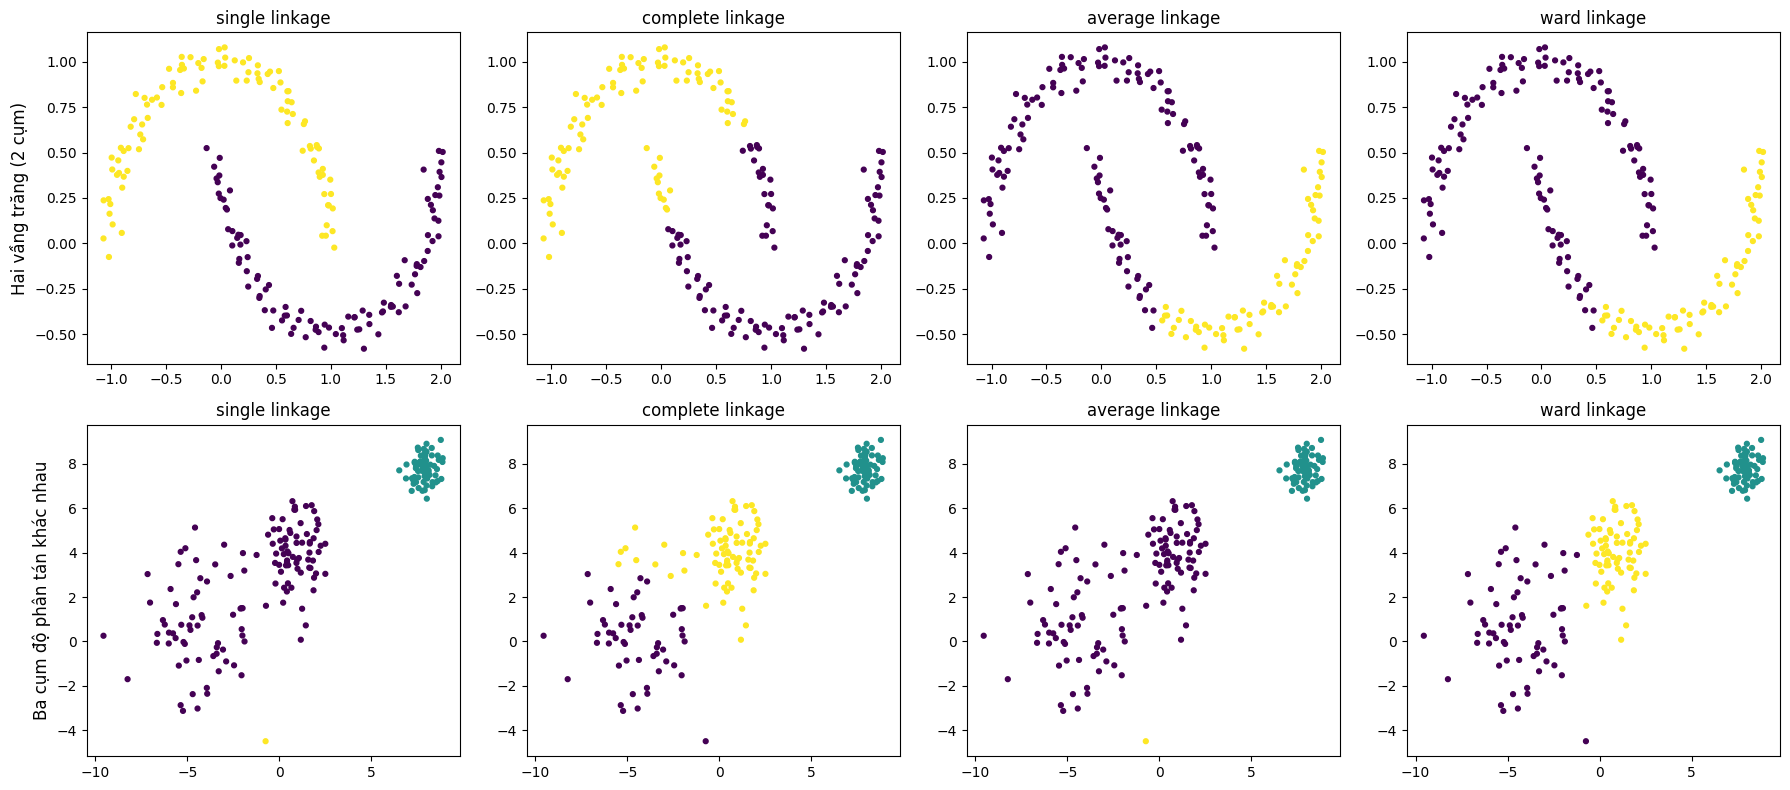

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for row, (data, k) in enumerate([(X_moons, 2), (X_blobs, 3)]):
    for col, method in enumerate(['single', 'complete', 'average', 'ward']):
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(data)
        axes[row, col].scatter(data[:, 0], data[:, 1], c=labels, cmap='viridis', s=12)
        axes[row, col].set_title('%s linkage' % method, fontsize=12)
axes[0, 0].set_ylabel('Hai vầng trăng (2 cụm)', fontsize=12)
axes[1, 0].set_ylabel('Ba cụm độ phân tán khác nhau', fontsize=12)
fig.tight_layout()
fig.savefig(IMAGES / 'linkage_comparison.png', dpi=150)